# Day 41: Customer Segmentation & Service Recommendation System

**Dataset:** the cleaned customer table from Day 40 (5,000 customers)

This notebook is the second of four days in the Customer Segmentation & Service Recommendation
System project. It turns the cleaned customer table into features for clustering (feature
engineering), groups the customers with K-Means, and evaluates how good the clusters are. Day 42
describes and names the segments, draws them in 2D, and builds the service recommendation
logic, and Day 43 finishes with a segment dashboard and business recommendations.

## 1. Import Libraries

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Folders and settings
DATA_DIR = Path("../datasets/veda_customers")
CLEAN_PATH = DATA_DIR / "cleaned" / "customers_cleaned.csv"
FEATURE_DIR = DATA_DIR / "features"
CLUSTER_DIR = DATA_DIR / "clustered"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
CLUSTER_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
REFERENCE_DATE = pd.Timestamp("2026-09-30")  # the same "today" used on Day 40

## 2. Load the Cleaned Customer Data

The table saved by the Day 40 preprocessing pipeline is loaded. It has one row per customer, no
duplicates, and no gaps except the satisfaction survey, which was left unfilled on purpose.

In [2]:
customers = pd.read_csv(CLEAN_PATH, parse_dates=["signup_date"])

print("Customers:", len(customers), "| columns:", customers.shape[1])
print("Columns with missing values:", customers.isna().sum()[lambda s: s > 0].to_dict())
customers.head()

Customers: 5000 | columns: 16
Columns with missing values: {'satisfaction_rating': 2266}


,customer_id,signup_date,customer_type,region,acquisition_channel,primary_interest,website_visits,avg_session_minutes,pages_per_visit,email_open_rate_pct,days_since_last_activity,service_inquiries,support_tickets,purchases,total_spend_inr,satisfaction_rating
0,C00001,2025-10-01,Student,International,Organic Search,Training Programs,38,7.7,7.4,59.6,13,2,0,3,20500,NaN
1,C00002,2025-10-01,Enterprise,South India,Direct,Training Programs,5,8.7,3.9,13.2,5,10,2,2,41400,4.0
2,C00003,2025-10-01,Enterprise,North India,Email,IT Services,16,7.2,3.7,45.8,20,21,1,2,129300,4.0
3,C00004,2025-10-01,Enterprise,West India,Referral,IT Services,15,3.5,4.4,6.7,8,0,0,3,112400,3.0
4,C00005,2025-10-01,Student,West India,Organic Search,Internships,22,10.2,7.1,60.8,5,0,3,2,15700,4.0


## 3. Feature Engineering

The raw columns cannot be given to K-Means as they are, for four reasons:

1. **Different scales.** Total spend reaches millions while an email open rate stops at 100, and K-Means is built on distances, so the biggest numbers would decide everything.
2. **Skew.** Spending, inquiries, and tickets have a few very large values, which would pull the cluster centers toward them.
3. **Overlap.** Several measures describe the same behavior (the four engagement measures are all related), and using all of them would give engagement four times the weight of spending.
4. **Different meanings.** Some columns describe behavior (what customers do) and some describe who the customers are, and the project wants groups based on behavior.

**Skew: log transform**

`log(1 + x)` pulls in the long tail and keeps zeros as zeros, which matters because many customers
have zero inquiries, tickets, or spending.

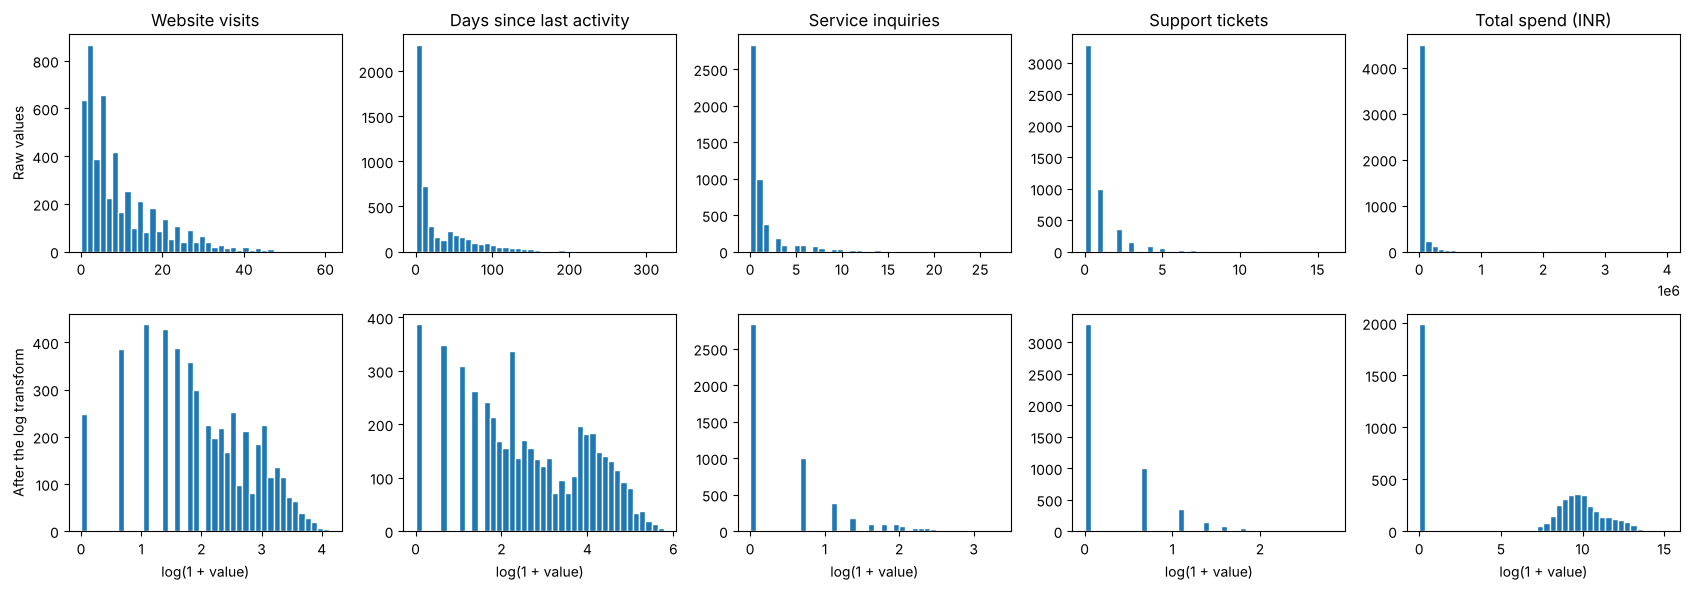

,skew_raw,skew_after_log
Website visits,1.56,-0.21
Days since last activity,2.22,0.02
Service inquiries,3.50,1.35
Support tickets,3.48,1.45
Total spend (INR),10.81,-0.27


In [3]:
skewed_columns = {
    "website_visits": "Website visits", "days_since_last_activity": "Days since last activity",
    "service_inquiries": "Service inquiries", "support_tickets": "Support tickets", "total_spend_inr": "Total spend (INR)",
}

fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for j, (col, label) in enumerate(skewed_columns.items()):
    axes[0, j].hist(customers[col], bins=40, edgecolor="white")
    axes[0, j].set_title(label)
    axes[1, j].hist(np.log1p(customers[col]), bins=40, edgecolor="white")
    axes[1, j].set_xlabel("log(1 + value)")
axes[0, 0].set_ylabel("Raw values")
axes[1, 0].set_ylabel("After the log transform")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "skew_raw": {label: customers[col].skew() for col, label in skewed_columns.items()},
    "skew_after_log": {label: np.log1p(customers[col]).skew() for col, label in skewed_columns.items()},
}).round(2)

**Tenure: should counts be turned into rates?**

A customer who signed up a year ago has had more time to visit, ask, and buy than one who signed
up last month, so dividing the counts by the time since sign-up might seem fairer. The data
decides: if the counts grew with tenure, a rate would be needed.

In [4]:
tenure = (REFERENCE_DATE - customers["signup_date"]).dt.days

pd.Series({
    col: customers[col].corr(tenure, method="spearman")
    for col in ["website_visits", "service_inquiries", "support_tickets", "purchases", "total_spend_inr"]
}).round(2).to_frame("spearman correlation with tenure")

,spearman correlation with tenure
website_visits,0.08
service_inquiries,0.07
support_tickets,0.05
purchases,0.14
total_spend_inr,0.14


**Overlap: combining the four engagement measures into one score**

Website visits, session length, pages per visit, and email open rate are all related. They are
combined into one **engagement score**: each measure is standardized (visits after the log
transform) and the four are averaged, so engagement counts once, like spending and recency.

In [5]:
engagement_parts = pd.DataFrame({
    "log_visits": np.log1p(customers["website_visits"]),
    "avg_session_minutes": customers["avg_session_minutes"],
    "pages_per_visit": customers["pages_per_visit"],
    "email_open_rate_pct": customers["email_open_rate_pct"],
})

print("Correlation between the four engagement measures:")
display(engagement_parts.corr().round(2))

engagement_score = ((engagement_parts - engagement_parts.mean()) / engagement_parts.std()).mean(axis=1)

pd.Series({col: engagement_score.corr(engagement_parts[col]) for col in engagement_parts}).round(2).to_frame("correlation with the engagement score")

Correlation between the four engagement measures:


,log_visits,avg_session_minutes,pages_per_visit,email_open_rate_pct
log_visits,1.00,0.58,0.54,0.60
avg_session_minutes,0.58,1.00,0.60,0.58
pages_per_visit,0.54,0.60,1.00,0.53
email_open_rate_pct,0.60,0.58,0.53,1.00


,correlation with the engagement score
log_visits,0.83
avg_session_minutes,0.84
pages_per_visit,0.81
email_open_rate_pct,0.82


**The engineered feature table**

Besides the engagement score, the table has the other behavior measures in their transformed form:
recency (`log_days_inactive`), service interest (`log_inquiries` and `log_tickets`), spending
(`log_spend`), and `tenure_days`. Two more features, the average order value and a buyer flag,
are kept in the table for describing the segments later, but not for clustering.

In [6]:
features = pd.DataFrame({
    "customer_id": customers["customer_id"],
    "tenure_days": tenure,
    "engagement_score": engagement_score,
    "log_days_inactive": np.log1p(customers["days_since_last_activity"]),
    "log_inquiries": np.log1p(customers["service_inquiries"]),
    "log_tickets": np.log1p(customers["support_tickets"]),
    "log_spend": np.log1p(customers["total_spend_inr"]),
    "avg_order_value_inr": np.where(customers["purchases"] > 0, customers["total_spend_inr"] / customers["purchases"].clip(lower=1), 0).round(0),
    "is_buyer": (customers["purchases"] > 0).astype(int),
})

features.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tenure_days,5000.0,147.24,110.00,0.00,46.00,130.00,241.00,364.00
engagement_score,5000.0,0.00,0.82,-1.64,-0.71,-0.11,0.74,2.36
log_days_inactive,5000.0,2.54,1.45,0.00,1.39,2.40,3.85,5.78
log_inquiries,5000.0,0.53,0.73,0.00,0.00,0.00,0.69,3.33
log_tickets,5000.0,0.33,0.52,0.00,0.00,0.00,0.69,2.83
log_spend,5000.0,6.04,5.02,0.00,0.00,8.68,10.10,15.20
avg_order_value_inr,5000.0,15237.87,38652.45,0.00,0.00,4700.00,11567.00,1002025.00
is_buyer,5000.0,0.60,0.49,0.00,0.00,1.00,1.00,1.00


**Which features are used for clustering, and why**

In [7]:
CLUSTER_FEATURES = ["engagement_score", "log_days_inactive", "log_inquiries", "log_tickets", "log_spend", "tenure_days"]

feature_choices = pd.DataFrame([
    ("engagement_score", "How actively the customer uses the website and emails", "Yes"),
    ("log_days_inactive", "Recency: how long since the customer was last active", "Yes"),
    ("log_inquiries", "Interest in Veda Technology services", "Yes"),
    ("log_tickets", "Support interactions", "Yes"),
    ("log_spend", "Money spent (the monetary value of the customer)", "Yes"),
    ("tenure_days", "How long the customer has been with Veda Technology (new or established)", "Yes"),
    ("purchases", "Number of purchases", "No: 0.94 correlated with spending, so it would count the same thing twice"),
    ("avg_order_value_inr, is_buyer", "Typical purchase size and a has-bought flag", "No: zero for non-buyers and mostly repeat spending"),
    ("satisfaction_rating", "Survey rating", "No: 45% of customers did not answer"),
    ("customer_type, primary_interest, acquisition_channel, region", "Who the customer is and how they arrived", "No: categories do not suit K-Means, so they are used to describe the segments on Day 42"),
], columns=["feature", "what it captures", "used for clustering"])

feature_choices

,feature,what it captures,used for clustering
0,engagement_score,How actively the customer uses the website and...,Yes
1,log_days_inactive,Recency: how long since the customer was last ...,Yes
2,log_inquiries,Interest in Veda Technology services,Yes
3,log_tickets,Support interactions,Yes
4,log_spend,Money spent (the monetary value of the customer),Yes
5,tenure_days,How long the customer has been with Veda Techn...,Yes
6,purchases,Number of purchases,"No: 0.94 correlated with spending, so it would..."
7,"avg_order_value_inr, is_buyer",Typical purchase size and a has-bought flag,No: zero for non-buyers and mostly repeat spen...
8,satisfaction_rating,Survey rating,No: 45% of customers did not answer
9,"customer_type, primary_interest, acquisition_c...",Who the customer is and how they arrived,"No: categories do not suit K-Means, so they ar..."


## 4. Preparing the Features for Clustering

K-Means measures distances, so the six features are **standardized** (mean 0 and standard
deviation 1). After this step, a difference of one standard deviation counts the same in every
feature.

In [8]:
scaler = StandardScaler()
X = scaler.fit_transform(features[CLUSTER_FEATURES])

scaled = pd.DataFrame(X, columns=[f"z_{col}" for col in CLUSTER_FEATURES])
scaled.agg(["mean", "std"]).round(2)

,z_engagement_score,z_log_days_inactive,z_log_inquiries,z_log_tickets,z_log_spend,z_tenure_days
mean,0.0,-0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


In [9]:
# Save the feature table (engineered features and the standardized clustering features) for Day 42
feature_table = pd.concat([features, scaled], axis=1)
feature_table.to_csv(FEATURE_DIR / "customer_features.csv", index=False)

print("Feature table saved to:", FEATURE_DIR / "customer_features.csv")
print("Rows:", len(feature_table), "| columns:", feature_table.shape[1])

Feature table saved to: ../datasets/veda_customers/features/customer_features.csv
Rows: 5000 | columns: 15


**Observation:** the log transform fixed most of the skew (website visits 1.56 to -0.21, days since last activity 2.22 to 0.02, and total spend 10.81 to -0.27). Inquiries and tickets stay somewhat skewed (3.50 to 1.35 and 3.48 to 1.45) because most customers have none, and a transform cannot spread out a pile of zeros. The counts barely grow with tenure (Spearman correlations of 0.05 to 0.14), so they were kept as counts and tenure became a feature of its own, because turning them into rates would divide by a number that has little to do with them. The four engagement measures are all related (0.53 to 0.60), so they were merged into one engagement score that correlates 0.81 to 0.84 with each of them, which keeps engagement from counting four times against spending. The clustering uses six features (engagement score, recency, inquiries, tickets, spending, and tenure), all standardized to a mean of 0 and a standard deviation of 1, and the feature table is saved in `datasets/veda_customers/features/`.

## 5. K-Means Clustering and Choosing the Number of Clusters

K-Means needs the number of clusters in advance, so it is run for 2 to 8 clusters and each
solution is judged with several measures instead of just one:

- **Inertia (the elbow method):** how tight the clusters are. It always falls as clusters are added, so the useful signal is where the fall flattens.
- **Silhouette score:** how much closer each customer is to its own cluster than to the nearest other cluster (from -1 to 1, higher is better).
- **Davies-Bouldin index:** how much the clusters overlap (lower is better).
- **Calinski-Harabasz index:** the ratio of the spread between clusters to the spread inside them (higher is better, but it tends to favor few clusters).
- **Stability:** whether the same customers end up together when the starting points change (with different random seeds) or when 20% of the customers are left out (20 random samples). It is measured with the adjusted Rand index, where 1 means identical groups.

Each run uses `n_init=20`, so K-Means starts from 20 different sets of random centers and keeps the best result.

In [10]:
rng = np.random.default_rng(RANDOM_STATE)
rows = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)

    # Stability 1: the same data with ten different random starting points
    seed_ari = np.mean([adjusted_rand_score(model.labels_, KMeans(n_clusters=k, n_init=1, random_state=seed).fit(X).labels_) for seed in range(100, 110)])

    # Stability 2: fit on a random 80% of the customers and compare the labels given to everyone
    boot_ari = []
    for b in range(20):
        sample = rng.choice(len(X), size=int(len(X) * 0.8), replace=False)
        partial = KMeans(n_clusters=k, n_init=10, random_state=b).fit(X[sample])
        boot_ari.append(adjusted_rand_score(model.labels_, partial.predict(X)))

    rows.append({
        "k": k, "inertia": model.inertia_, "silhouette": silhouette_score(X, model.labels_),
        "davies_bouldin": davies_bouldin_score(X, model.labels_), "calinski_harabasz": calinski_harabasz_score(X, model.labels_),
        "smallest_cluster_pct": np.bincount(model.labels_).min() / len(X) * 100,
        "seed_stability_ari": seed_ari, "sample_stability_ari": np.mean(boot_ari),
    })

k_table = pd.DataFrame(rows).set_index("k")
k_table.insert(1, "inertia_drop_pct", -k_table["inertia"].pct_change() * 100)
k_table.round(3)

,inertia,inertia_drop_pct,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_pct,seed_stability_ari,sample_stability_ari
k,,,,,,,,
2,21236.041,NaN,0.280,1.451,2062.639,44.48,0.997,0.992
3,16884.190,20.493,0.294,1.375,1940.868,18.36,0.965,0.960
4,13672.286,19.023,0.292,1.266,1988.774,17.42,0.947,0.992
5,12461.520,8.856,0.266,1.325,1757.508,15.84,0.729,0.987
6,11541.651,7.382,0.264,1.415,1597.363,8.02,0.660,0.962
7,10704.123,7.257,0.232,1.467,1500.112,7.94,0.727,0.881
8,9959.690,6.955,0.228,1.496,1434.945,7.62,0.703,0.963


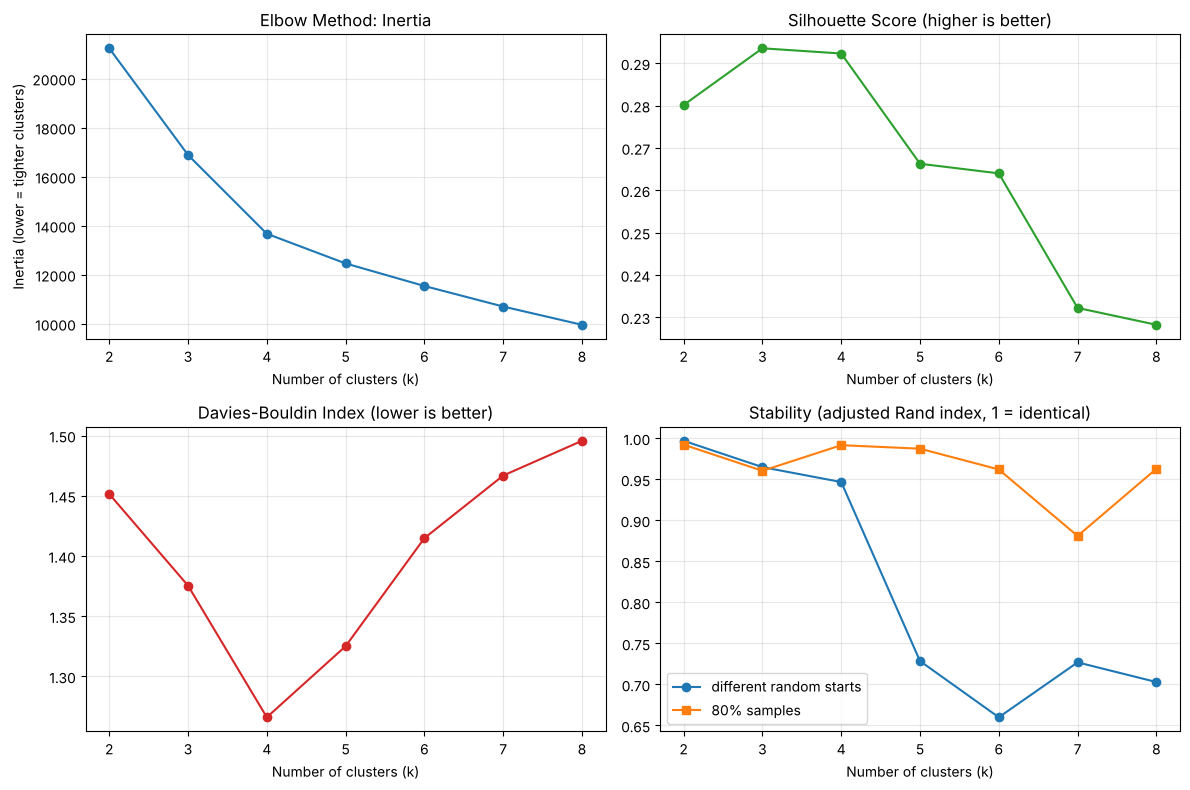

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
ks = k_table.index

axes[0, 0].plot(ks, k_table["inertia"], marker="o")
axes[0, 0].set_title("Elbow Method: Inertia")
axes[0, 0].set_ylabel("Inertia (lower = tighter clusters)")

axes[0, 1].plot(ks, k_table["silhouette"], marker="o", color="tab:green")
axes[0, 1].set_title("Silhouette Score (higher is better)")

axes[1, 0].plot(ks, k_table["davies_bouldin"], marker="o", color="tab:red")
axes[1, 0].set_title("Davies-Bouldin Index (lower is better)")

axes[1, 1].plot(ks, k_table["seed_stability_ari"], marker="o", label="different random starts")
axes[1, 1].plot(ks, k_table["sample_stability_ari"], marker="s", label="80% samples")
axes[1, 1].set_title("Stability (adjusted Rand index, 1 = identical)")
axes[1, 1].legend()

for ax in axes.flat:
    ax.set_xlabel("Number of clusters (k)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Observation:** four clusters is the best-supported choice. The elbow is at 4: the inertia falls by about 20% from 2 to 3 clusters and from 3 to 4, but by only 9% from 4 to 5 and by about 7% for each cluster after that. The silhouette score is highest for 3 clusters (0.294), but 4 clusters is practically tied with it (0.292), and the Davies-Bouldin index is best for 4 clusters (1.27 against 1.38 for 3 and 1.33 for 5). The Calinski-Harabasz index prefers 2 clusters (2,063 against 1,989 for 4), which is typical for that index, since it favors few clusters. Stability settles the choice: with 4 clusters the groups are almost identical across different random starts (adjusted Rand index of 0.95) and across samples of 80% of the customers (0.99), but from 5 clusters on, different starting points give different groups (0.73 at 5 and 0.66 at 6), which means the extra clusters are not real, stable groups. With 4 clusters the smallest group still holds 17% of the customers, enough to act on. The four example segments in the project hints, and the four hidden behavior patterns used to generate the data, point the same way, so the result is partly built into the simulation. The silhouette of about 0.29 is low, though, and a common rule of thumb calls values between 0.26 and 0.50 weak structure: the customers form overlapping groups and not sharply separated types.

**The final model**

K-Means is fitted with the chosen number of clusters. K-Means numbers its clusters at random, so
they are renumbered from the **largest to the smallest**, which makes the numbers easy to read
and keeps them stable for the next days.

In [12]:
K = 4

kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X)

order = np.argsort(-np.bincount(kmeans.labels_))
renumber = {old: new for new, old in enumerate(order)}
labels = np.array([renumber[label] for label in kmeans.labels_])

clustered = customers.copy()
clustered["tenure_days"] = tenure
clustered["cluster"] = labels
clustered["is_buyer"] = clustered["purchases"] > 0

sizes = clustered["cluster"].value_counts().sort_index()
pd.DataFrame({"customers": sizes, "share_pct": (sizes / len(clustered) * 100).round(1)})

,customers,share_pct
cluster,,
0,1517,30.3
1,1369,27.4
2,1243,24.9
3,871,17.4


## 6. Cluster Evaluation

**What the clusters look like in the standardized features**

Each cell is the average of the cluster on a feature, in standard deviations from the average
customer. A value of +1 means one standard deviation above the average customer.

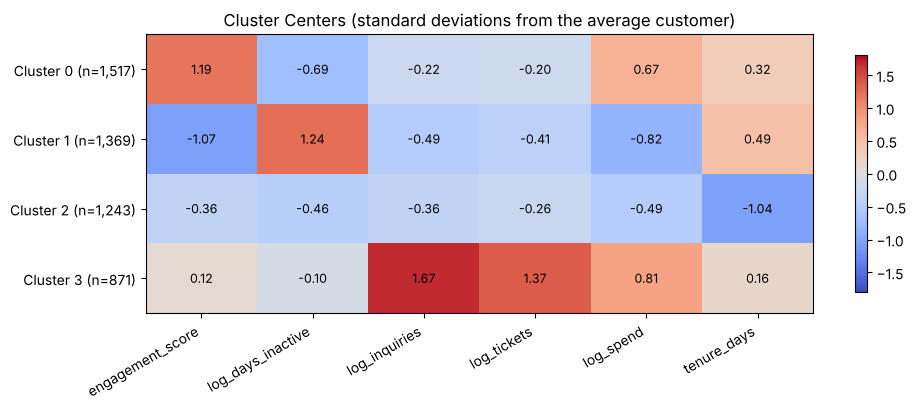

In [13]:
centers = pd.DataFrame(X, columns=CLUSTER_FEATURES).groupby(labels).mean()

fig, ax = plt.subplots(figsize=(10, 4.2))
image = ax.imshow(centers, cmap="coolwarm", vmin=-1.8, vmax=1.8, aspect="auto")
ax.set_xticks(range(len(CLUSTER_FEATURES)))
ax.set_xticklabels(CLUSTER_FEATURES, rotation=30, ha="right")
ax.set_yticks(range(K))
ax.set_yticklabels([f"Cluster {c} (n={sizes[c]:,})" for c in range(K)])
for i in range(K):
    for j in range(len(CLUSTER_FEATURES)):
        ax.text(j, i, f"{centers.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Cluster Centers (standard deviations from the average customer)")
fig.colorbar(image, ax=ax, shrink=0.85)
plt.tight_layout()
plt.show()

**The same clusters in the original units**

These tables use the cleaned values (visits, days, INR) so that the clusters can be read as
behavior. Clear names for the segments come on Day 42.

In [14]:
profile = clustered.groupby("cluster").agg(
    customers=("customer_id", "count"), avg_visits=("website_visits", "mean"), avg_session_min=("avg_session_minutes", "mean"),
    avg_pages=("pages_per_visit", "mean"), avg_email_open_pct=("email_open_rate_pct", "mean"),
    avg_days_inactive=("days_since_last_activity", "mean"), avg_inquiries=("service_inquiries", "mean"),
    avg_tickets=("support_tickets", "mean"), avg_tenure_days=("tenure_days", "mean"),
)
profile["buyers_pct"] = clustered.groupby("cluster")["is_buyer"].mean() * 100
profile["median_spend_inr"] = clustered.groupby("cluster")["total_spend_inr"].median()
profile["avg_spend_inr"] = clustered.groupby("cluster")["total_spend_inr"].mean()
profile["share_of_total_spend_pct"] = clustered.groupby("cluster")["total_spend_inr"].sum() / clustered["total_spend_inr"].sum() * 100
profile["avg_satisfaction"] = clustered.groupby("cluster")["satisfaction_rating"].mean()
profile.round(1).T

cluster,0,1,2,3
customers,1517.0,1369.0,1243.0,871.0
avg_visits,19.4,3.1,6.3,7.9
avg_session_min,9.3,2.9,4.5,7.0
avg_pages,6.4,2.5,3.5,5.1
avg_email_open_pct,54.6,15.1,30.4,28.0
avg_days_inactive,6.1,86.3,9.2,16.8
avg_inquiries,0.6,0.3,0.4,6.1
avg_tickets,0.4,0.2,0.3,2.4
avg_tenure_days,182.8,200.9,32.4,164.9
buyers_pct,94.9,22.6,40.6,87.0


**Observation:** each cluster stands out on a different set of features. Cluster 0 (1,517 customers, 30%) is the most engaged: an average of 19.4 website visits, 54.6% of emails opened, and activity 6 days ago, with 95% having bought (median spend INR 18,100) and the highest satisfaction (4.3). It makes up 23% of the spending. Cluster 1 (1,369, 27%) is almost inactive: 3.1 visits, 15% of emails opened, last active 86 days ago on average, 23% having bought, a median spend of 0, and only 1% of the spending. Cluster 2 (1,243, 25%) are recent sign-ups, with an average of 32 days since signing up against 165 to 201 days for the others, moderate engagement (6.3 visits and 30% of emails opened), 41% having bought, and 3% of the spending. Cluster 3 (871, 17%) is the service-heavy group, with 6.1 inquiries and 2.4 support tickets per customer against 0.3 to 0.6 and 0.2 to 0.4 in the other clusters, 87% having bought, and a median spend of INR 97,900. This group, 17% of the customers, accounts for 73% of all spending. Names for the segments come on Day 42.

**Silhouette: how well each customer fits its cluster**

The silhouette of a customer compares its distance to its own cluster with its distance to the
nearest other cluster. A value near 1 means a clear fit, near 0 means the customer sits on the
border between two clusters, and below 0 means it may belong to another cluster.

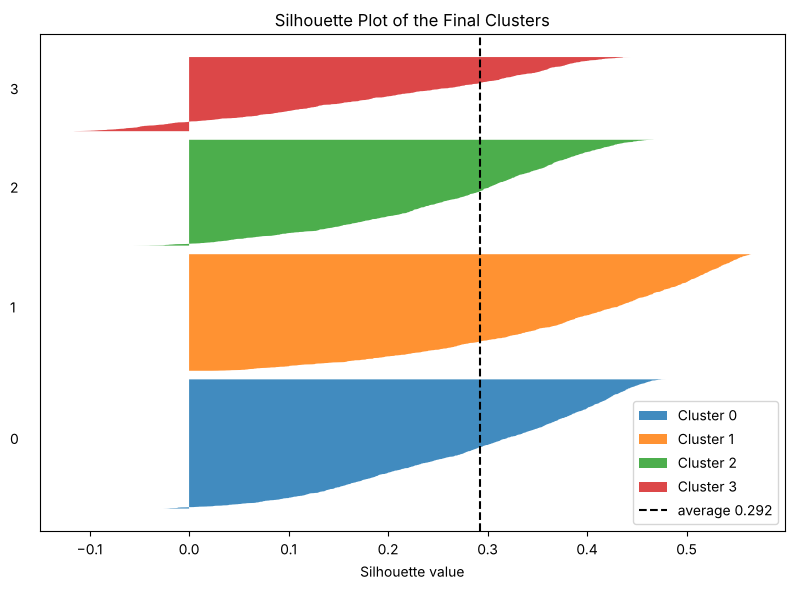

,average_silhouette,customers_with_negative_silhouette_pct
0,0.285,1.055
1,0.382,0.000
2,0.266,1.770
3,0.201,12.744


In [15]:
silhouette_values = silhouette_samples(X, labels)
overall_silhouette = silhouette_values.mean()

fig, ax = plt.subplots(figsize=(8, 6))
y_start = 10
for c in range(K):
    values = np.sort(silhouette_values[labels == c])
    ax.fill_betweenx(np.arange(y_start, y_start + len(values)), 0, values, alpha=0.85, label=f"Cluster {c}")
    ax.text(-0.18, y_start + len(values) / 2, str(c))
    y_start += len(values) + 100
ax.axvline(overall_silhouette, color="black", linestyle="--", label=f"average {overall_silhouette:.3f}")
ax.set_title("Silhouette Plot of the Final Clusters")
ax.set_xlabel("Silhouette value")
ax.set_yticks([])
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "average_silhouette": pd.Series(silhouette_values).groupby(labels).mean(),
    "customers_with_negative_silhouette_pct": pd.Series(silhouette_values < 0).groupby(labels).mean() * 100,
}).round(3)

**Observation:** the average silhouette is 0.292, and 3.0% of the customers have a negative value, which means they may fit another cluster better. The clusters are not equally well defined. Cluster 1 (the inactive customers) is the best separated (0.382, with no negative values), clusters 0 and 2 are in the middle (0.285 and 0.266, with 1.1% and 1.8% negative values), and cluster 3 (the service-heavy customers) is the weakest (0.201), with 12.7% of its customers closer to another cluster. Cluster 3 is also the most spread out: the average squared distance of its customers to their own center is 4.5 (in standardized units), against 2.0 to 2.7 for the other clusters. The silhouette of every customer is saved, so Day 42 can treat customers near a border with less confidence when recommending services.

**Are the clusters stable?**

The solution was already tested for different random starts and for 20% samples in the previous
section. A second question is whether the clusters depend on the feature choices made in this
notebook. K-Means is run again with four other feature sets and the new clusters are compared
with the final ones using the adjusted Rand index (1 means the same groups, and 0 means no more
agreement than chance).

In [16]:
def cluster_with(table, k=K):
    scaled_table = StandardScaler().fit_transform(table)
    return KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(scaled_table)


alternatives = {
    "Without tenure_days (5 features)": features[[c for c in CLUSTER_FEATURES if c != "tenure_days"]],
    "Without the log transform (raw counts and spending)": pd.DataFrame({
        "engagement_score": features["engagement_score"], "days_inactive": customers["days_since_last_activity"],
        "inquiries": customers["service_inquiries"], "tickets": customers["support_tickets"],
        "spend": customers["total_spend_inr"], "tenure_days": tenure}),
    "Four engagement measures instead of the score (9 features)": pd.concat([
        engagement_parts, features[["log_days_inactive", "log_inquiries", "log_tickets", "log_spend", "tenure_days"]]], axis=1),
    "All raw numeric columns, no engineering (9 features)": customers[[
        "website_visits", "avg_session_minutes", "pages_per_visit", "email_open_rate_pct", "days_since_last_activity",
        "service_inquiries", "support_tickets", "total_spend_inr"]].assign(tenure_days=tenure),
}

pd.DataFrame({
    name: {"agreement_with_final_clusters_ari": adjusted_rand_score(labels, cluster_with(table))}
    for name, table in alternatives.items()
}).T.round(3)

,agreement_with_final_clusters_ari
Without tenure_days (5 features),0.682
Without the log transform (raw counts and spending),0.702
Four engagement measures instead of the score (9 features),0.879
"All raw numeric columns, no engineering (9 features)",0.761


**Observation:** the clusters are stable under resampling and different starting points (adjusted Rand indexes of 0.95 and 0.99 in the previous section), and they mostly survive other feature choices: using the four engagement measures separately gives almost the same groups (0.88), the raw columns without any engineering give 0.76, and removing the log transform or tenure gives 0.70 and 0.68. The agreement is not perfect because the borders move, which is expected when groups overlap. The test without tenure is informative: 95% to 98% of the customers of clusters 0, 1, and 3 still stay together, but the recent sign-ups of cluster 2 are split (53% of them still form a group of mostly recent customers, with an average tenure of 62 days, 30% join the engaged group, and 15% join the inactive group), so tenure matters mainly for the new-customer group.

**Do the clusters make business sense? A check with columns that were not used**

Customer type, primary interest, and acquisition channel were deliberately left out of the
clustering. If the clusters only reflect real behavior differences, they should still differ in
who the customers are and what they want. Each row below shows the percentage of the cluster.

In [17]:
for col in ["customer_type", "primary_interest", "acquisition_channel"]:
    print(col)
    display((pd.crosstab(clustered["cluster"], clustered[col], normalize="index") * 100).round(0).astype(int))

customer_type


customer_type,Educational Institution,Enterprise,Small Business,Startup,Student,Unknown,Working Professional
cluster,,,,,,,
0,2,1,5,4,57,3,27
1,4,4,12,10,38,2,31
2,5,2,13,11,40,2,27
3,10,18,33,24,7,3,5


primary_interest


primary_interest,Digital Services,IT Services,Internships,Training Programs,Unknown
cluster,,,,,
0,8,7,38,44,2
1,27,18,23,30,2
2,21,19,28,30,2
3,36,50,4,8,2


acquisition_channel


acquisition_channel,Direct,Email,Organic Search,Paid Ads,Referral,Social Media,Unknown
cluster,,,,,,,
0,12,15,25,9,19,19,1
1,15,4,30,18,4,28,1
2,14,5,26,17,10,26,1
3,18,14,23,10,27,7,2


**Observation:** the clusters differ clearly in columns that were not used. Cluster 3 is the business cluster: 85% of its customers are Small Business, Startup, Enterprise, or Educational Institution customers (13% to 31% in the other clusters), and 86% are interested in IT Services or Digital Services (15% to 46% elsewhere). Cluster 0 is the opposite: 84% are Students or Working Professionals, and 83% are interested in Training Programs or Internships (12% in cluster 3). Referral and Email are more common acquisition channels in clusters 0 and 3 (19% and 15% in cluster 0, 27% and 14% in cluster 3) than in clusters 1 and 2 (4% to 10% Referral and 4% to 5% Email), which lean on Social Media and Paid Ads (26% to 28% and 17% to 18%). Clusters 1 and 2 look much alike in who the customers are (about two thirds are Students or Working Professionals, and the interests are mixed), so they are told apart by behavior alone: inactive in one case and recent in the other. Because the simulation generated these columns from the same hidden behavior patterns, this check shows that K-Means recovered the built-in structure, but on real data it would be independent evidence.

In [18]:
# Save the clustered customers and the evaluation by number of clusters for Day 42
output = customers.copy()
output["cluster"] = labels
output["silhouette"] = silhouette_values.round(4)
output.to_csv(CLUSTER_DIR / "customers_clustered.csv", index=False)
k_table.round(4).to_csv(CLUSTER_DIR / "cluster_evaluation_by_k.csv")

print("Saved:", CLUSTER_DIR / "customers_clustered.csv", "| rows:", len(output), "| columns:", output.shape[1])
print("Saved:", CLUSTER_DIR / "cluster_evaluation_by_k.csv")

Saved: ../datasets/veda_customers/clustered/customers_clustered.csv | rows: 5000 | columns: 18
Saved: ../datasets/veda_customers/clustered/cluster_evaluation_by_k.csv


## Outcome

This notebook turned the cleaned customer table into six clustering features and found four customer clusters with K-Means. Feature engineering fixed the skew of spending, recency, and the activity counts with a log transform, merged the four overlapping engagement measures into one engagement score, kept tenure as its own feature because the counts do not grow with it, and standardized everything; the feature table is saved for Day 42. K-Means was run for 2 to 8 clusters, and 4 was chosen because the elbow, the Davies-Bouldin index, and stability all agree on it and the silhouette is practically tied with its best value (0.292 against 0.294 for 3 clusters), while from 5 clusters on the groups stop being stable. The four clusters are an engaged group (30% of customers, 19 visits on average), an inactive group (27%, last active 86 days ago on average), recent sign-ups (25%, 32 days since signing up on average), and a service-heavy group (17% of customers but 73% of all spending, with 6.1 inquiries per customer, mostly business customers). The evaluation also shows the limits: the average silhouette is only 0.29, so the groups overlap, the service-heavy cluster is the least well defined (12.7% of its customers are closer to another cluster), and the clusters agree 0.68 to 0.88 with those from other feature choices, with the recent sign-ups the most sensitive. Because the simulation was built with four hidden behavior patterns, finding four clusters is partly built in, so these results show that the method works and not that real Veda Technology customers form four groups. The clustered customers and the evaluation by number of clusters are saved in `datasets/veda_customers/clustered/` for Day 42.